# Module 08, Part 2: Instability, mode collapse and the fixes that stuck

This notebook is the runnable companion to Part 2 of the Module 08 learning content. It checks, with code:

1. Whether the original and the non-saturating generator losses behave differently when the whole game is trained, on a grid of 25 Gaussians where every mode can be counted.
2. What mode collapse looks like in numbers (modes covered, precision, recall) and in the generated class counts on real digits.
3. Whether a Wasserstein critic with a gradient penalty (WGAN-GP) fixes it, and whether the penalty does what it claims (a critic gradient norm close to one).

Numbers are averages over three seeds, with the single seeds shown where they matter. The digits GANs take several minutes each to run, so the whole notebook takes about 15 minutes on two CPU cores.

In [1]:
import math, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np
import torch
from sklearn.datasets import load_digits


def load_data(seed=0, test_fraction=0.2):
    """Return (X_train, y_train, X_test, y_test). Pixels are scaled to [0, 1] and flattened to 64 values."""
    d = load_digits()
    X = (d.data / 16.0).astype(np.float32)
    y = d.target.astype(np.int64)
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_fraction)
    te, tr = idx[:n_test], idx[n_test:]
    return (torch.tensor(X[tr]), torch.tensor(y[tr]), torch.tensor(X[te]), torch.tensor(y[te]))


def one_hot(y, n=10):
    return torch.nn.functional.one_hot(y, n).float()

In [3]:
import math
import numpy as np
import torch


def ring_of_gaussians(n, n_modes=8, radius=2.0, std=0.05, seed=0):
    """n points from a mixture of n_modes Gaussians evenly spaced on a circle. Returns (points, mode index)."""
    g = torch.Generator().manual_seed(seed)
    k = torch.randint(0, n_modes, (n,), generator=g)
    ang = 2 * math.pi * k.float() / n_modes
    centers = radius * torch.stack([torch.cos(ang), torch.sin(ang)], 1)
    return centers + std * torch.randn(n, 2, generator=g), k


def mode_centers(n_modes=8, radius=2.0):
    ang = 2 * math.pi * torch.arange(n_modes).float() / n_modes
    return radius * torch.stack([torch.cos(ang), torch.sin(ang)], 1)


def mode_coverage(samples, n_modes=8, radius=2.0, std=0.05, tol=6.0):
    """Return (modes covered, share of samples within tol*std of a mode centre).
    A mode counts as covered if at least 1 percent of the samples land near it."""
    c = mode_centers(n_modes, radius)
    d = torch.cdist(samples, c)
    near = d.min(1)
    ok = near.values < tol * std
    counts = torch.bincount(near.indices[ok], minlength=n_modes)
    return int((counts >= 0.01 * len(samples)).sum()), float(ok.float().mean())


def grid_centers(side=5, spacing=1.0):
    r = (torch.arange(side).float() - (side - 1) / 2) * spacing
    return torch.stack(torch.meshgrid(r, r, indexing="ij"), -1).reshape(-1, 2)


def grid_of_gaussians(n, side=5, spacing=1.0, std=0.05, seed=0):
    """n points from a side-by-side grid of Gaussians (25 modes for side=5). Returns (points, mode index)."""
    g = torch.Generator().manual_seed(seed)
    c = grid_centers(side, spacing)
    k = torch.randint(0, len(c), (n,), generator=g)
    return c[k] + std * torch.randn(n, 2, generator=g), k


def grid_coverage(samples, side=5, spacing=1.0, std=0.05, tol=6.0):
    """(modes covered, share of samples within tol*std of a mode centre); a mode counts if it holds at least 0.4 percent of the samples."""
    c = grid_centers(side, spacing)
    near = torch.cdist(samples, c).min(1)
    ok = near.values < tol * std
    counts = torch.bincount(near.indices[ok], minlength=len(c))
    return int((counts >= 0.2 / len(c) * len(samples)).sum()), float(ok.float().mean())

In [4]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F


def mlp(d_in, d_out, d_hidden=64, layers=2, act=nn.ReLU, spectral=False):
    mods, d = [], d_in
    for _ in range(layers):
        lin = nn.Linear(d, d_hidden)
        mods += [nn.utils.spectral_norm(lin) if spectral else lin, act()]
        d = d_hidden
    last = nn.Linear(d, d_out)
    mods.append(nn.utils.spectral_norm(last) if spectral else last)
    return nn.Sequential(*mods)


class Generator(nn.Module):
    """Maps noise (and an optional one-hot label) to a sample. out_act='sigmoid' for images in [0, 1], None for raw coordinates."""

    def __init__(self, d_noise=8, d_out=2, d_hidden=64, n_classes=0, out_act=None):
        super().__init__()
        self.d_noise, self.n_classes = d_noise, n_classes
        self.net = mlp(d_noise + n_classes, d_out, d_hidden)
        self.out_act = out_act

    def forward(self, z, c=None):
        out = self.net(z if c is None else torch.cat([z, c], 1))
        return torch.sigmoid(out) if self.out_act == "sigmoid" else out


class Discriminator(nn.Module):
    """Returns a logit (a real-valued score for the Wasserstein critic). With n_classes > 0 it also sees the label."""

    def __init__(self, d_in=2, d_hidden=64, n_classes=0, spectral=False):
        super().__init__()
        self.net = mlp(d_in + n_classes, 1, d_hidden, act=lambda: nn.LeakyReLU(0.2), spectral=spectral)

    def forward(self, x, c=None):
        return self.net(x if c is None else torch.cat([x, c], 1)).squeeze(1)


def gradient_penalty(D, real, fake, c=None):
    """WGAN-GP: penalize the critic's gradient norm, measured on random points between real and fake, for deviating from 1."""
    t = torch.rand(len(real), 1)
    x = (t * real + (1 - t) * fake).requires_grad_(True)
    g, = torch.autograd.grad(D(x, c).sum(), x, create_graph=True)
    return ((g.norm(dim=1) - 1) ** 2).mean(), g.norm(dim=1).mean().item()


def train_gan(G, D, X, y_onehot=None, objective="nonsat", steps=2000, batch_size=128, lr_g=2e-3, lr_d=2e-3,
              n_critic=1, gp_weight=10.0, seed=0, betas=(0.5, 0.9), log_every=0):
    """Alternate discriminator and generator updates.
    objective: 'minimax'  generator minimizes log(1 - D(G(z)))   (the original, saturating loss)
               'nonsat'   generator maximizes log D(G(z))        (the standard fix)
               'wgan_gp'  critic maximizes D(real) - D(fake) with a gradient penalty, generator maximizes D(G(z))
    Returns a dict of histories: d_loss, g_loss, d_real (mean probability or score on real), d_fake, g_grad (norm of the loss gradient at the generator output)."""
    torch.manual_seed(seed)
    opt_g = torch.optim.Adam(G.parameters(), lr=lr_g, betas=betas)
    opt_d = torch.optim.Adam(D.parameters(), lr=lr_d, betas=betas)
    h = {"d_loss": [], "g_loss": [], "d_real": [], "d_fake": [], "g_grad": [], "gp_norm": []}
    n = len(X)
    for step in range(steps):
        for _ in range(n_critic):
            idx = torch.randint(0, n, (batch_size,))
            real = X[idx]
            c = None if y_onehot is None else y_onehot[idx]
            with torch.no_grad():
                fake = G(torch.randn(batch_size, G.d_noise), c)
            dr, df = D(real, c), D(fake, c)
            if objective == "wgan_gp":
                gp, gpn = gradient_penalty(D, real, fake, c)
                d_loss = df.mean() - dr.mean() + gp_weight * gp
                h["gp_norm"].append(gpn)
            else:
                d_loss = F.binary_cross_entropy_with_logits(dr, torch.ones_like(dr)) + \
                         F.binary_cross_entropy_with_logits(df, torch.zeros_like(df))
            opt_d.zero_grad(); d_loss.backward(); opt_d.step()
        idx = torch.randint(0, n, (batch_size,))
        c = None if y_onehot is None else y_onehot[idx]
        fake = G(torch.randn(batch_size, G.d_noise), c)
        fake.retain_grad()
        df = D(fake, c)
        if objective == "minimax":
            g_loss = -F.binary_cross_entropy_with_logits(df, torch.zeros_like(df))   # = log(1 - D(G(z)))
        elif objective == "nonsat":
            g_loss = F.binary_cross_entropy_with_logits(df, torch.ones_like(df))     # = -log D(G(z))
        else:
            g_loss = -df.mean()
        opt_g.zero_grad(); g_loss.backward(); opt_g.step()
        h["d_loss"].append(float(d_loss.detach())); h["g_loss"].append(float(g_loss.detach()))
        h["g_grad"].append(float(fake.grad.norm(dim=1).mean()))
        if objective == "wgan_gp":
            h["d_real"].append(float(dr.mean().detach())); h["d_fake"].append(float(df.mean().detach()))
        else:
            h["d_real"].append(float(torch.sigmoid(dr).mean().detach())); h["d_fake"].append(float(torch.sigmoid(df).mean().detach()))
    return h


@torch.no_grad()
def sample_gan(G, n, seed=0, label=None):
    g = torch.Generator().manual_seed(seed)
    z = torch.randn(n, G.d_noise, generator=g)
    c = None if G.n_classes == 0 else torch.nn.functional.one_hot(torch.full((n,), label), G.n_classes).float()
    return G(z, c)

In [5]:
import numpy as np
import torch
import torch.nn as nn
from scipy import linalg


class FeatureNet(nn.Module):
    """A small classifier trained on real digits. Its hidden layer plays the role Inception plays in FID."""

    def __init__(self, d_in=64, d_feat=32):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(d_in, 64), nn.ReLU(), nn.Linear(64, d_feat), nn.ReLU())
        self.head = nn.Linear(d_feat, 10)

    def features(self, x):
        return self.body(x)

    def forward(self, x):
        return self.head(self.body(x))


def train_feature_net(X, y, epochs=60, seed=0):
    torch.manual_seed(seed)
    net = FeatureNet()
    opt = torch.optim.Adam(net.parameters(), lr=3e-3)
    for _ in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 64):
            idx = perm[i:i + 64]
            loss = nn.functional.cross_entropy(net(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
    return net


@torch.no_grad()
def get_features(net, X):
    return net.features(X).numpy().astype(np.float64)


def frechet_distance(fa, fb):
    """Frechet distance between Gaussians fitted to two sets of features (the quantity behind FID)."""
    mu_a, mu_b = fa.mean(0), fb.mean(0)
    eps = 1e-6 * np.eye(fa.shape[1])
    ca, cb = np.cov(fa, rowvar=False) + eps, np.cov(fb, rowvar=False) + eps
    covmean = linalg.sqrtm(ca @ cb)
    covmean = covmean.real
    return float(((mu_a - mu_b) ** 2).sum() + np.trace(ca) + np.trace(cb) - 2 * np.trace(covmean))


def _knn_radius(F, k):
    d = np.linalg.norm(F[:, None] - F[None], axis=-1)
    return np.sort(d, axis=1)[:, k]


def precision_recall(real, fake, k=3):
    """Precision: share of generated points that land inside the real data's neighbourhood.
    Recall: share of real points that land inside the generated data's neighbourhood. (k-nearest-neighbour balls.)"""
    r_real, r_fake = _knn_radius(real, k), _knn_radius(fake, k)
    d = np.linalg.norm(fake[:, None] - real[None], axis=-1)
    precision = float((d <= r_real[None]).any(1).mean())
    recall = float((d.T <= r_fake[None]).any(1).mean())
    return precision, recall


def nearest_train_distance(samples, train):
    """Pixel-space distance from each generated image to its nearest training image. Near zero means copying."""
    d = torch.cdist(samples, train)
    return d.min(1).values

## 1. The original and the non-saturating loss on 25 modes

The data is 5,000 points from a 5 by 5 grid of Gaussians (standard deviation 0.05, spacing 1). The generator has only a two-dimensional noise input, so it has to place its mass carefully.
Both objectives train for 4,000 steps with identical networks and seeds. A mode counts as covered if at least 0.8 percent of the samples (one fifth of its fair share) land within six standard deviations of it.

In [6]:
Xg, _ = grid_of_gaussians(5000)
grid_results = {}
def run_grid(obj, seed, **kw):
    torch.manual_seed(seed)
    G, D = Generator(d_noise=2, d_hidden=128), Discriminator(d_hidden=128)
    t0 = time.time()
    h = train_gan(G, D, Xg, objective=obj, seed=seed, **kw)
    s = sample_gan(G, 2000, seed=9)
    return grid_coverage(s), s, h, time.time() - t0

for obj, kw in [("minimax", dict(steps=4000, lr_g=2e-3, lr_d=2e-3)),
                ("nonsat", dict(steps=4000, lr_g=2e-3, lr_d=2e-3)),
                ("wgan_gp", dict(steps=4000, lr_g=5e-4, lr_d=5e-4, n_critic=3, betas=(0.5, 0.999)))]:
    grid_results[obj] = [run_grid(obj, seed, **kw) for seed in range(3)]
print("objective   seed   modes covered (of 25)   share near a mode   seconds")
for obj, runs in grid_results.items():
    for seed, ((m, q), _, _, sec) in enumerate(runs):
        print(f"{obj:9s}   {seed:4d}   {m:19d}   {q:17.3f}   {sec:7.1f}")

objective   seed   modes covered (of 25)   share near a mode   seconds
minimax        0                    25               0.807      12.1
minimax        1                    24               0.768      11.0
minimax        2                    25               0.709      11.4
nonsat         0                    24               0.737      10.5
nonsat         1                    25               0.734      24.6
nonsat         2                    25               0.744      59.7
wgan_gp        0                    13               0.174      33.1
wgan_gp        1                     6               0.211      30.6
wgan_gp        2                     9               0.356      31.3


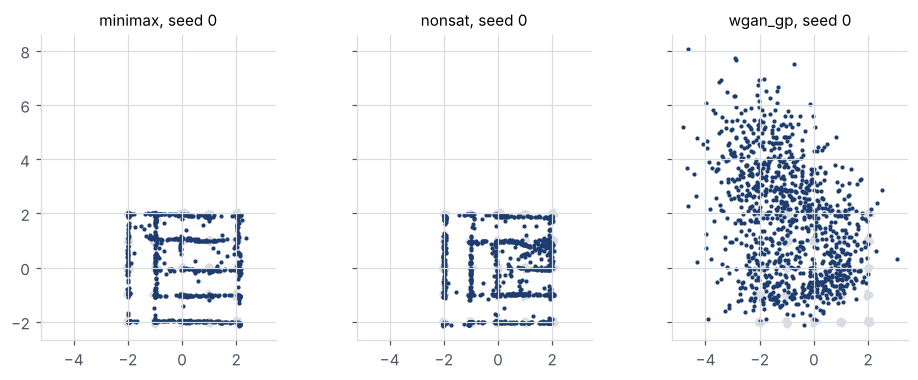

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.6), sharex=True, sharey=True)
for ax, obj in zip(axes, ["minimax", "nonsat", "wgan_gp"]):
    s = grid_results[obj][0][1]
    ax.scatter(Xg[:1000, 0], Xg[:1000, 1], s=3, color=RULE)
    ax.scatter(s[:1000, 0], s[:1000, 1], s=3, color=NAVY)
    ax.set_title(f"{obj}, seed 0", fontsize=10); ax.set_aspect("equal")
plt.show()

Read the table before reading the picture. The count of modes covered says how much of the data the generator can reach at all, and the share of samples near a mode says whether what it produces is sharp.
These two can disagree: a generator can reach every mode with smeared samples, or sharpen a handful of modes and ignore the rest. That second pattern is mode collapse.

## 2. Mode collapse on real digits

The same question on the digits. We train the same generator and discriminator architecture (16 noise values, 128 hidden units) with the non-saturating loss and with WGAN-GP, three seeds each, then score 359 generated
images with the feature network from Module 07: Fréchet distance to the test set, precision, recall, and the digit each image is assigned to by the classifier. If a generator has collapsed onto a few digits, the class counts will show it.

In [8]:
Xtr, ytr, Xte, yte = load_data()
net = train_feature_net(Xtr, ytr)
fte = get_features(net, Xte)
real_counts = np.bincount(yte.numpy(), minlength=10)
print("class counts of the 359 test images:", real_counts.tolist())

digit_results = {}
cfgs = {"nonsat": dict(objective="nonsat", lr_g=5e-4, lr_d=2e-4, betas=(0.5, 0.999)),
        "wgan_gp": dict(objective="wgan_gp", lr_g=5e-4, lr_d=5e-4, betas=(0.5, 0.999), n_critic=3)}
for name, kw in cfgs.items():
    runs = []
    for seed in range(3):
        torch.manual_seed(seed)
        G = Generator(d_noise=16, d_out=64, d_hidden=128, out_act="sigmoid")
        D = Discriminator(d_in=64, d_hidden=128)
        t0 = time.time()
        h = train_gan(G, D, Xtr, steps=4000, seed=seed, **kw)
        s = sample_gan(G, 359, seed=9)
        f = get_features(net, s)
        fd = frechet_distance(f, fte)
        p, r = precision_recall(fte, f)
        counts = np.bincount(net(s).argmax(1).numpy(), minlength=10)
        runs.append(dict(fd=fd, p=p, r=r, counts=counts, samples=s, hist=h, gen=G))
        print(f"{name:8s} seed {seed}: Frechet {fd:7.1f}  precision {p:.2f}  recall {r:.2f}  classes present {int((counts > 0).sum())}/10  ({time.time() - t0:.0f} s)", flush=True)
    digit_results[name] = runs

class counts of the 359 test images: [27, 35, 36, 29, 30, 40, 44, 39, 38, 41]


nonsat   seed 0: Frechet   110.9  precision 0.69  recall 0.00  classes present 7/10  (12 s)


nonsat   seed 1: Frechet   295.5  precision 0.96  recall 0.00  classes present 3/10  (12 s)


nonsat   seed 2: Frechet   193.4  precision 0.74  recall 0.00  classes present 4/10  (12 s)


wgan_gp  seed 0: Frechet     6.2  precision 0.77  recall 0.91  classes present 10/10  (35 s)


wgan_gp  seed 1: Frechet     3.8  precision 0.76  recall 0.91  classes present 10/10  (35 s)


wgan_gp  seed 2: Frechet     5.3  precision 0.75  recall 0.90  classes present 10/10  (34 s)


method     Frechet (mean)   precision   recall    class counts, seed 0
nonsat             199.9        0.79     0.00    [90, 0, 0, 111, 26, 7, 0, 89, 14, 22]
wgan_gp              5.1        0.76     0.90    [55, 38, 44, 21, 33, 36, 37, 35, 33, 27]


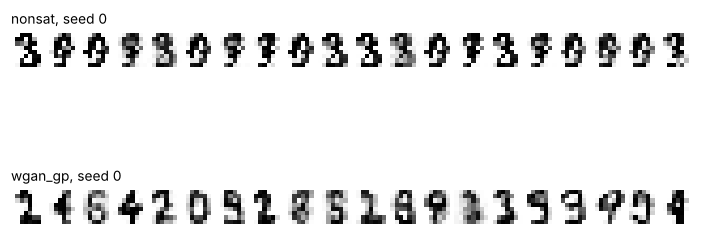

In [9]:
print("method     Frechet (mean)   precision   recall    class counts, seed 0")
for name, runs in digit_results.items():
    print(f"{name:8s}   {np.mean([r['fd'] for r in runs]):13.1f}   {np.mean([r['p'] for r in runs]):9.2f}   {np.mean([r['r'] for r in runs]):6.2f}    {runs[0]['counts'].tolist()}")
fig, axes = plt.subplots(2, 1, figsize=(8, 3.4))
for ax, name in zip(axes, digit_results):
    s = digit_results[name][0]["samples"][:20].reshape(-1, 8, 8)
    ax.imshow(np.concatenate(list(s), 1), cmap="gray_r"); ax.axis("off"); ax.set_title(f"{name}, seed 0", fontsize=9, loc="left")
plt.show()

Compare the two rows of the table on recall first. A recall near zero means that the generated images do not cover the region of feature space where the real images are, even when the precision is respectable.
The class counts say which digits are missing. This is the practical signature of mode collapse: a generator that is good at a few things and cannot be made to produce the rest.

## 3. Does the gradient penalty do what it says?

The Wasserstein critic is only valid if it is 1-Lipschitz, which for a differentiable critic means its gradient norm is at most one. The penalty pushes the gradient norm on points between real and generated
samples towards one. We read it off the training history of the first WGAN-GP digit run, and compare the critic's score gap with the training progress.

critic gradient norm on interpolated points: first 100 steps 0.91, last 500 steps 1.01
critic score gap (real minus fake): first 100 steps 1.27, last 500 steps 0.30


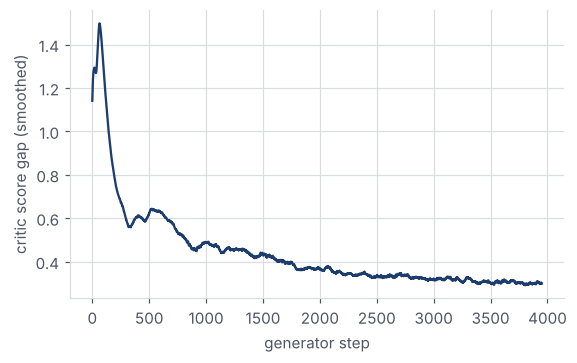

In [10]:
h = digit_results["wgan_gp"][0]["hist"]
gp = np.array(h["gp_norm"])
print(f"critic gradient norm on interpolated points: first 100 steps {gp[:100].mean():.2f}, last 500 steps {gp[-500:].mean():.2f}")
score_gap = np.array(h["d_real"]) - np.array(h["d_fake"])
print(f"critic score gap (real minus fake): first 100 steps {score_gap[:100].mean():.2f}, last 500 steps {score_gap[-500:].mean():.2f}")
fig, ax = plt.subplots(figsize=(5.8, 3.4))
ax.plot(np.convolve(score_gap, np.ones(50) / 50, mode="valid"), color=NAVY)
ax.set_xlabel("generator step"); ax.set_ylabel("critic score gap (smoothed)")
plt.show()

Two things to read. The penalty holds the critic's gradient norm near one, which is the condition the theory needs. And the score gap, which estimates the Wasserstein distance between the generated and the real
distributions, falls as the generator improves. Unlike the discriminator loss of the standard GAN, this number tracks sample quality, so it is a useful thing to plot during training.